In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import PIL
import tensorflow as tf
from tensorflow import keras
from glob import glob
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pathlib

data_dir = pathlib.Path("//content/drive/MyDrive/Colab Notebooks/chest_xray")


In [ ]:
# @title
!unzip '/content/drive/MyDrive/Colab Notebooks/dataset.zip' -d '/content/drive/MyDrive/Colab Notebooks'


Streaming output truncated to the last 5000 lines.
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: /content/drive/MyDrive/Colab Notebooks/chest_xr

In [4]:
data_dir.exists()



True

In [5]:
DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/chest_xray"

train_path = DATASET_PATH + "/train"
valid_path = DATASET_PATH + "/val"
test_path  = DATASET_PATH + "/test"

IMAGE_SIZE = [224, 224]

print("Train exists:", os.path.exists(train_path))
print("Val exists:", os.path.exists(valid_path))
print("Test exists:", os.path.exists(test_path))


Train exists: True
Val exists: True
Test exists: True


In [6]:
resnet = ResNet50(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#for layer in resnet.layers:
    #layer.trainable = False



unfreezing last 30 and keeping upper layers frozen


In [7]:
for layer in resnet.layers[-30:]:
    layer.trainable = True


In [8]:
for layer in resnet.layers[:-30]:
    layer.trainable = False


In [9]:
# @title
folders = glob(train_path + "/*")
from tensorflow.keras.layers import Dropout
x = Flatten()(resnet.output)
x = Dropout(0.5)(x)
prediction = Dense(len(folders), activation='softmax')(x)
model = Model(inputs=resnet.input, outputs=prediction)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,788,418 (90.75 MB)

 Trainable params: 14,650,882 (55.89 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [ ]:
#model.compile(
  #loss='categorical_crossentropy',
  #optimizer='adam',
  #metrics=['accuracy']
)

SyntaxError: unmatched ')' (ipython-input-2732205703.py, line 5)

low learning rate for model

In [10]:


model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-5),  # very small LR
    metrics=['accuracy']
)


In [11]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
valid_datagen = ImageDataGenerator(rescale = 1./255)
test_datagen = ImageDataGenerator(rescale = 1./255)

In [12]:
training_set = train_datagen.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

valid_set = valid_datagen.flow_from_directory(
    valid_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [13]:
#fitting the model

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "pneumonia_resnet50.h5",
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]


a = model.fit(
    training_set,
    validation_data=valid_set,
    epochs=20,
    callbacks=callbacks,   # <-- use the full callbacks list
    steps_per_epoch=len(training_set),
    validation_steps=len(valid_set)
)





/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.8229 - loss: 0.5424
Epoch 1: val_loss improved from inf to 1.57495, saving model to pneumonia_resnet50.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 1654s 10s/step - accuracy: 0.8232 - loss: 0.5415 - val_accuracy: 0.5000 - val_loss: 1.5749 - learning_rate: 1.0000e-05
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 709ms/step - accuracy: 0.9009 - loss: 0.2776
Epoch 2: val_loss improved from 1.57495 to 1.21505, saving model to pneumonia_resnet50.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 716ms/step - accuracy: 0.9009 - loss: 0.2775 - val_accuracy: 0.5000 - val_loss: 1.2150 - learning_rate: 1.0000e-05
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 716ms/step - accuracy: 0.8962 - loss: 0.2993
Epoch 3: val_loss improved from 1.21505 to 0.94535, saving model to pneumonia_resnet50.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 722ms/step - accuracy: 0.8962 - loss: 0.2991 - val_accuracy: 0.6875 - val_loss: 0.9453 - learning_rate: 1.0000e-05
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.9122 - loss: 0.2344
Epoch 4: val_loss improved from 0.94535 to 0.47955, saving model to pneumonia_resnet50.h5


163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 722ms/step - accuracy: 0.9122 - loss: 0.2344 - val_accuracy: 0.7500 - val_loss: 0.4796 - learning_rate: 1.0000e-05
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.9145 - loss: 0.2161
Epoch 5: val_loss did not improve from 0.47955
163/163 ━━━━━━━━━━━━━━━━━━━━ 140s 714ms/step - accuracy: 0.9145 - loss: 0.2161 - val_accuracy: 0.7500 - val_loss: 0.8054 - learning_rate: 1.0000e-05
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - accuracy: 0.9286 - loss: 0.1809
Epoch 6: val_loss did not improve from 0.47955
163/163 ━━━━━━━━━━━━━━━━━━━━ 117s 716ms/step - accuracy: 0.9286 - loss: 0.1810 - val_accuracy: 0.6250 - val_loss: 2.2795 - learning_rate: 1.0000e-05
Epoch 7/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 719ms/step - accuracy: 0.9294 - loss: 0.1874
Epoch 7: val_loss did not improve from 0.47955
163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 723ms/step - accuracy: 0.9294 - loss: 0.1874 - val_accuracy: 0.6875 - val_loss: 0.7242 - learning_rate: 1.0000e-05

163/163 ━━━━━━━━━━━━━━━━━━━━ 143s 728ms/step - accuracy: 0.9478 - loss: 0.1351 - val_accuracy: 0.8750 - val_loss: 0.3345 - learning_rate: 3.0000e-06
Epoch 13/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.9393 - loss: 0.1652
Epoch 13: val_loss did not improve from 0.33454
163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 724ms/step - accuracy: 0.9394 - loss: 0.1650 - val_accuracy: 0.8125 - val_loss: 0.6156 - learning_rate: 3.0000e-06
Epoch 14/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 728ms/step - accuracy: 0.9479 - loss: 0.1412
Epoch 14: val_loss did not improve from 0.33454
163/163 ━━━━━━━━━━━━━━━━━━━━ 119s 729ms/step - accuracy: 0.9479 - loss: 0.1412 - val_accuracy: 0.8750 - val_loss: 0.3790 - learning_rate: 3.0000e-06
Epoch 15/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - accuracy: 0.9542 - loss: 0.1200
Epoch 15: val_loss did not improve from 0.33454
163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 725ms/step - accuracy: 0.9542 - loss: 0.1199 - val_accuracy: 0.8750 - val_loss: 0.4096 - learning_rate: 3.00

163/163 ━━━━━━━━━━━━━━━━━━━━ 118s 722ms/step - accuracy: 0.9632 - loss: 0.1028 - val_accuracy: 0.8750 - val_loss: 0.2274 - learning_rate: 1.0000e-06


In [14]:
!rm -rf /content/chest_xray/test/.ipynb_checkpoints


In [15]:
test_loss, test_acc = model.evaluate(test_set)
print("Test Accuracy:", test_acc)



20/20 ━━━━━━━━━━━━━━━━━━━━ 188s 10s/step - accuracy: 0.8723 - loss: 0.3524
Test Accuracy: 0.8685897588729858


In [16]:
model.save("/content/pneumonia_resnet50.h5")



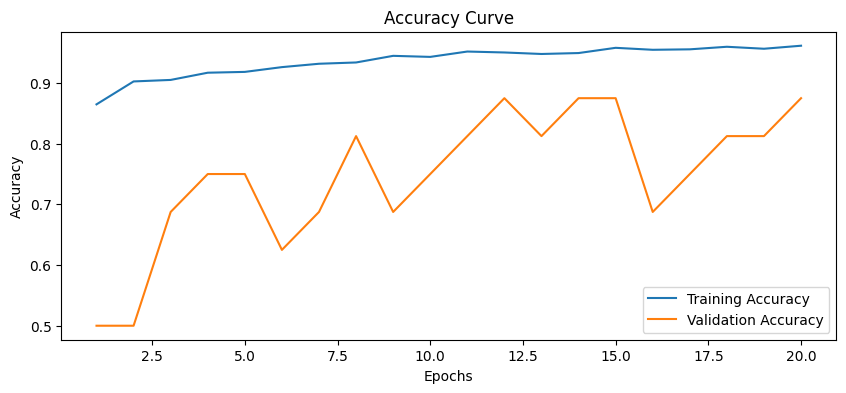

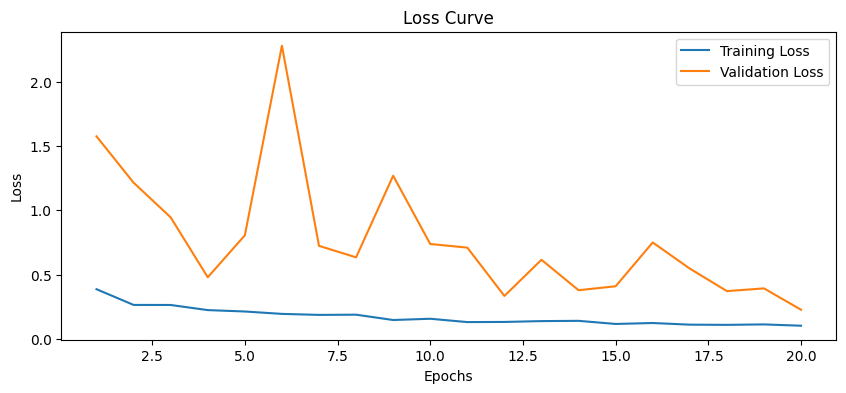

In [20]:
def plot_training_curves(history):
    acc = a.history['accuracy']
    val_acc = a.history['val_accuracy']
    loss = a.history['loss']
    val_loss = a.history['val_loss']



    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(10,4))
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.xlabel('Epochs'); plt.ylabel('Accuracy')
    plt.legend(); plt.title('Accuracy Curve'); plt.show()

    plt.figure(figsize=(10,4))
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.xlabel('Epochs'); plt.ylabel('Loss')
    plt.legend(); plt.title('Loss Curve'); plt.show()

plot_training_curves(a)


20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 332ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.80      0.86      0.83       234
   PNEUMONIA       0.91      0.87      0.89       390

    accuracy                           0.87       624
   macro avg       0.86      0.87      0.86       624
weighted avg       0.87      0.87      0.87       624



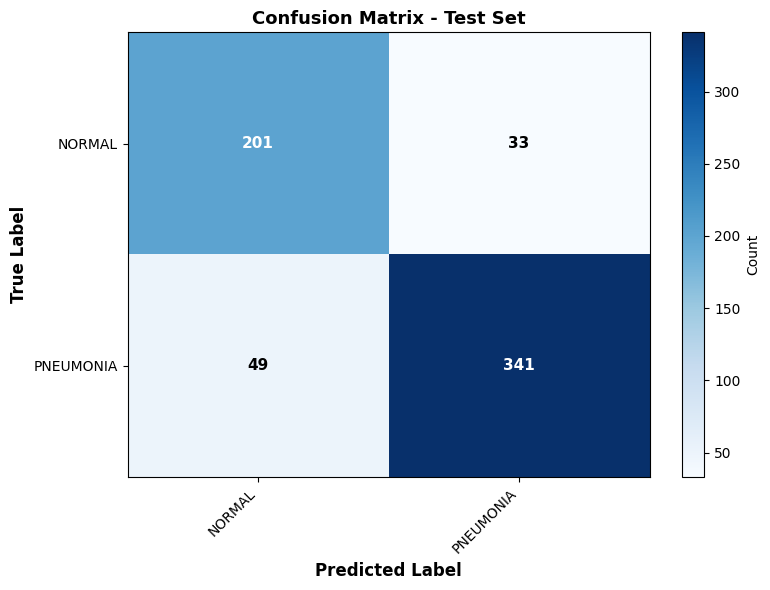

PERFORMANCE METRICS
Accuracy  : 0.8686
Precision : 0.8714
Recall    : 0.8686
F1 Score  : 0.8694



In [30]:

y_true = test_set.classes
y_pred_probs = model.predict(test_set)
y_pred = np.argmax(y_pred_probs, axis=1)
class_names = list(test_set.class_indices.keys())


print("\n" + "="*70)
print("CLASSIFICATION REPORT")
print("="*70)
print(classification_report(y_true, y_pred, target_names=class_names))


cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap='Blues', aspect='auto')
plt.xticks(range(len(class_names)), class_names, rotation=45, ha='right')
plt.yticks(range(len(class_names)), class_names)
plt.colorbar(label='Count')


for i in range(len(class_names)):
    for j in range(len(class_names)):
        text_color = "white" if cm[i, j] > cm.max() / 2 else "black"
        plt.text(j, i, cm[i, j], ha='center', va='center',
                color=text_color, fontweight='bold', fontsize=11)

plt.xlabel("Predicted Label", fontsize=12, fontweight='bold')
plt.ylabel("True Label", fontsize=12, fontweight='bold')
plt.title("Confusion Matrix - Test Set", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("="*70)
print("PERFORMANCE METRICS")
print("="*70)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print("="*70 + "\n")

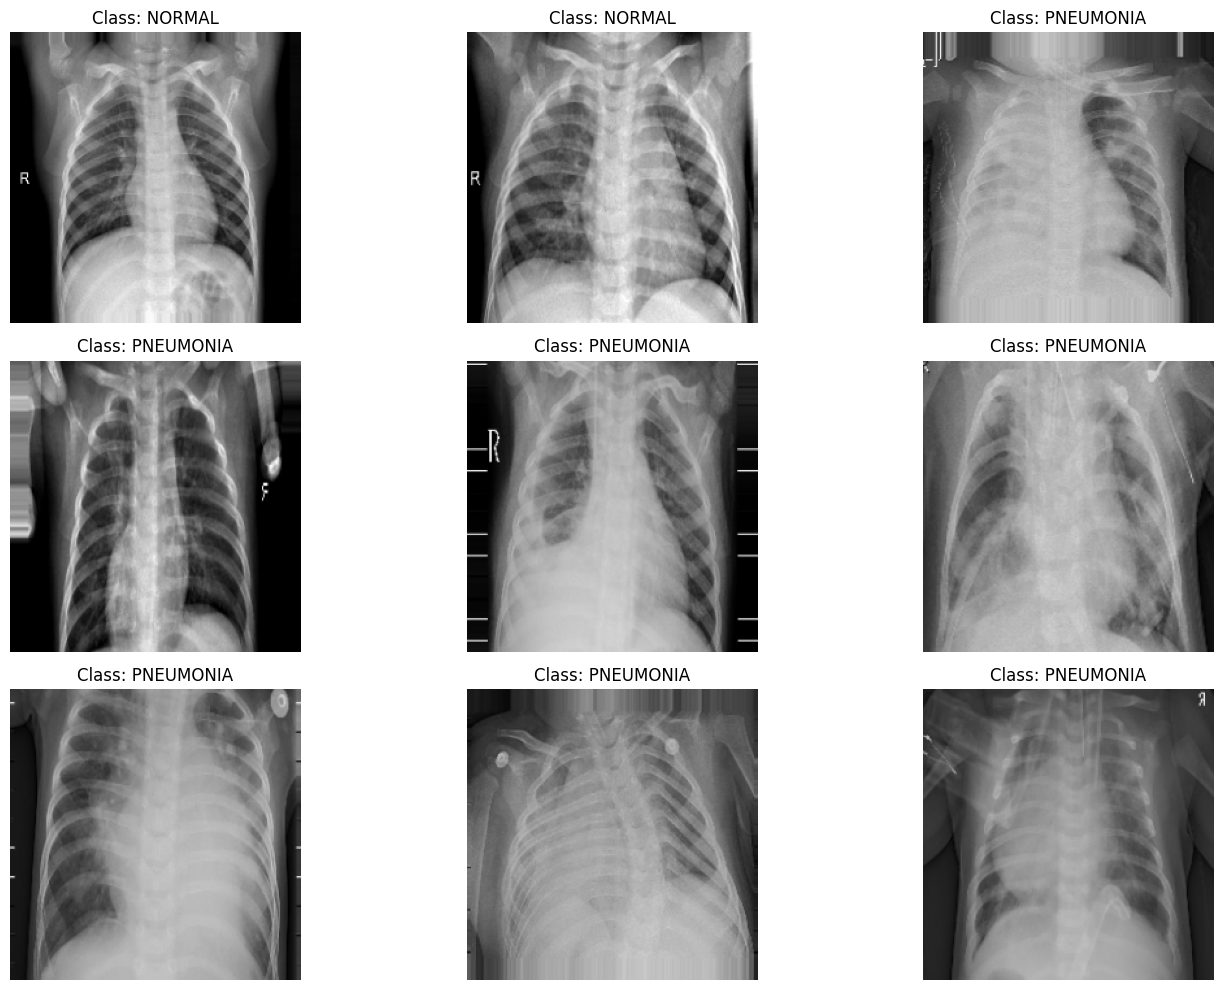

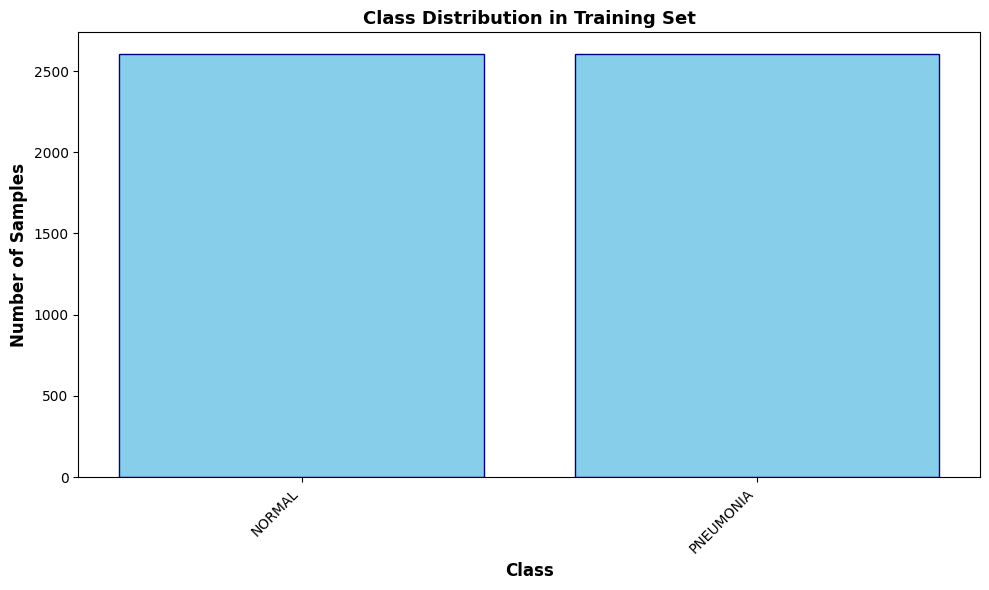

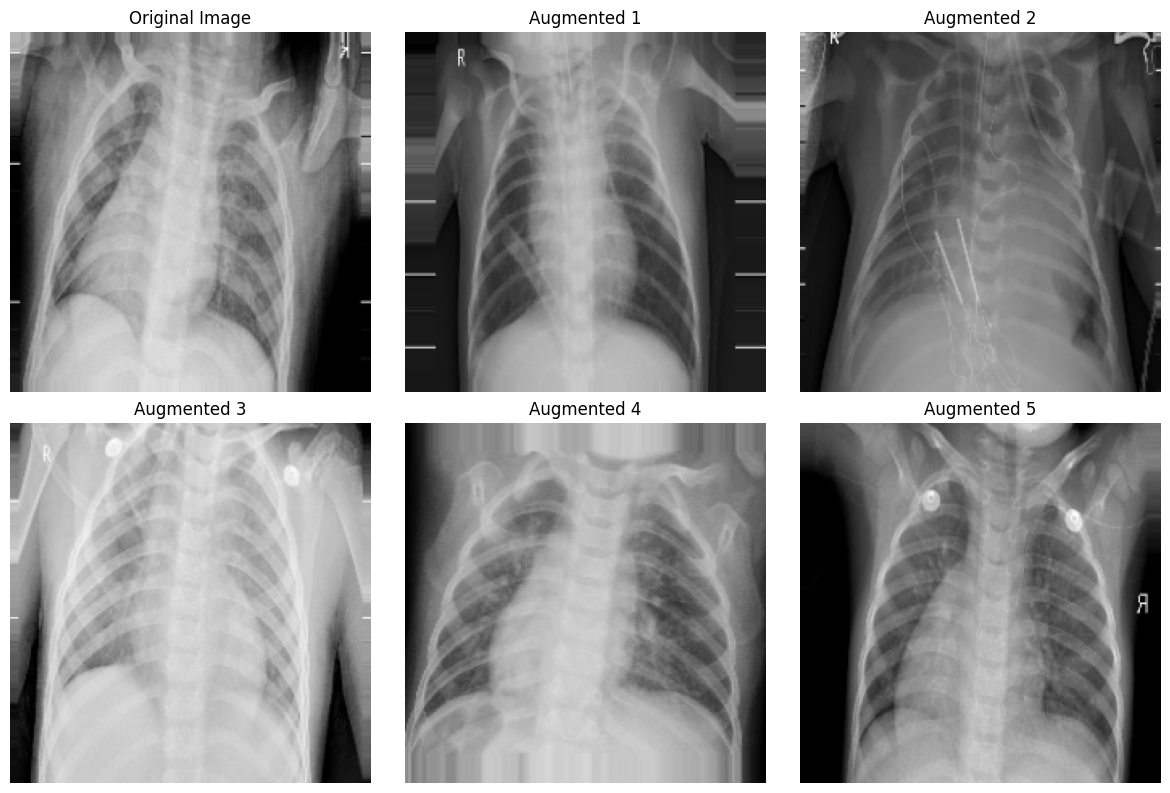

DATASET STATISTICS
Training Set:
  - Total samples: 5216
  - Number of classes: 2
  - Batch size: 32
  - Classes: ['NORMAL', 'PNEUMONIA']

Validation Set:
  - Total samples: 16
  - Number of classes: 2

Test Set:
  - Total samples: 624
  - Number of classes: 2


In [26]:

plt.figure(figsize=(15, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    images, labels = next(iter(training_set))
    random_idx = np.random.randint(0, len(images))
    plt.imshow(images[random_idx])
    class_names = list(training_set.class_indices.keys())
    class_idx = np.argmax(labels[random_idx])
    plt.title(f"Class: {class_names[class_idx]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


class_names = list(training_set.class_indices.keys())
class_counts = {cls: training_set.samples // len(class_names) for cls in class_names}

plt.figure(figsize=(10, 6))
plt.bar(class_names, class_counts.values(), color='skyblue', edgecolor='navy')
plt.xlabel('Class', fontsize=12, fontweight='bold')
plt.ylabel('Number of Samples', fontsize=12, fontweight='bold')
plt.title('Class Distribution in Training Set', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 8))


images, labels = next(iter(training_set))
original_img = images[0]

plt.subplot(2, 3, 1)
plt.imshow(original_img)
plt.title('Original Image')
plt.axis('off')


for i in range(1, 6):
    images, _ = next(iter(training_set))
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[0])
    plt.title(f'Augmented {i}')
    plt.axis('off')

plt.tight_layout()
plt.show()


print("="*70)
print("DATASET STATISTICS")
print("="*70)
print(f"Training Set:")
print(f"  - Total samples: {training_set.samples}")
print(f"  - Number of classes: {training_set.num_classes}")
print(f"  - Batch size: {training_set.batch_size}")
print(f"  - Classes: {class_names}")
print()
print(f"Validation Set:")
print(f"  - Total samples: {valid_set.samples}")
print(f"  - Number of classes: {valid_set.num_classes}")
print()
print(f"Test Set:")
print(f"  - Total samples: {test_set.samples}")
print(f"  - Number of classes: {test_set.num_classes}")
print("="*70)


In [18]:
print(valid_set.samples)
print(training_set.samples)


16
5216


In [31]:
!ls /content



drive  pneumonia_resnet50.h5  sample_data


In [32]:
from google.colab import files

files.download('pneumonia_resnet50.h5')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>